In [3]:
from qiskit import __version__
print(__version__)

2.5.0


In [12]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity, Pauli, DensityMatrix, partial_trace
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_aer.library import SaveDensityMatrix, SaveStatevector, SetDensityMatrix
from qiskit import transpile 
import numpy as np
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.circuit.library import HGate, UnitaryGate, IGate
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter, LogLocator, LogFormatterMathtext
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit
from mpmath import mp
from matplotlib.patches import Circle

In [5]:
def inf_to_error(infidelity_list, num_qubits):
    error_rates_list = []
    dimension = 2**num_qubits
    for infidelity in infidelity_list:
        error_rates_list.append( infidelity * (dimension / (dimension - 1)) )
    
    return error_rates_list

In [6]:
mp.dps = 100

# Fixed point
zstar = mp.findroot(
    lambda z: z**3 + z**2 + z - 1,
    (mp.mpf("0.5"), mp.mpf("0.6"))
)
xstar = mp.sqrt(1 - zstar**2)

lam = xstar
q0 = 1 + zstar**2

# Taylor expansion order
N = 120

# X(t) = sum a[n]*t**n
# Z(t) = sum b[n]*t**n
# Q(t) = 1 + Z(t)**2 = sum q[n]*t**n
a = [mp.mpf(0)] * (N + 1)
b = [mp.mpf(0)] * (N + 1)
q = [mp.mpf(0)] * (N + 1)

a[0], b[0] = xstar, zstar
a[1] = b[1] = mp.mpf(1)

q[0] = q0
q[1] = 2 * zstar

# Recursively determine coefficients
for n in range(2, N + 1):

    bb = mp.fsum(
        b[k] * b[n-k] for k in range(1, n)
    )
    aa = mp.fsum(
        a[k] * a[n-k] for k in range(1, n)
    )
    qx = mp.fsum(
        q[k] * lam**(n-k) * a[n-k]
        for k in range(1, n)
    )
    qz = mp.fsum(
        q[k] * lam**(n-k) * b[n-k]
        for k in range(1, n)
    )

    A = mp.matrix([
        [q0 * lam**n, 2*xstar*zstar - 2],
        [-2*xstar, q0*lam**n + 2*zstar**2]
    ])

    rhs = mp.matrix([
        -xstar*bb - qx,
        aa - zstar*bb - qz
    ])

    result = mp.lu_solve(A, rhs)

    a[n] = result[0]
    b[n] = result[1]

    q[n] = 2*zstar*b[n] + bb

# Evaluate the stable manifold
t = mp.mpf("-0.02")

x_in = mp.fsum(a[n]*t**n for n in range(N+1))
z_in = mp.fsum(b[n]*t**n for n in range(N+1))

print("x_in =", mp.nstr(x_in, 30))
print("z_in =", mp.nstr(z_in, 30))

# Verify physicality
r_squared = x_in**2 + z_in**2

print("|r|^2 =", mp.nstr(r_squared, 30))

x_in = 0.821680873558761730519437953156
z_in = 0.526236101185028884090535408586
|r|^2 = 0.952083892162709740483223969911


In [7]:
x = mp.mpf(x_in)
z = mp.mpf(z_in)

rounds = 400

infidelity_list = []
success_probabilities = []

def infidelity(x, z):
    return (1 - xstar*x - zstar*z) / 2

infidelity_list.append(infidelity(x, z))

for r in range(rounds):
    denom = 1 + z**2

    p_success = denom / 2

    x_new = 2*z / denom
    z_new = x**2 / denom

    x, z = x_new, z_new

    success_probabilities.append(p_success)
    infidelity_list.append(infidelity(x, z))

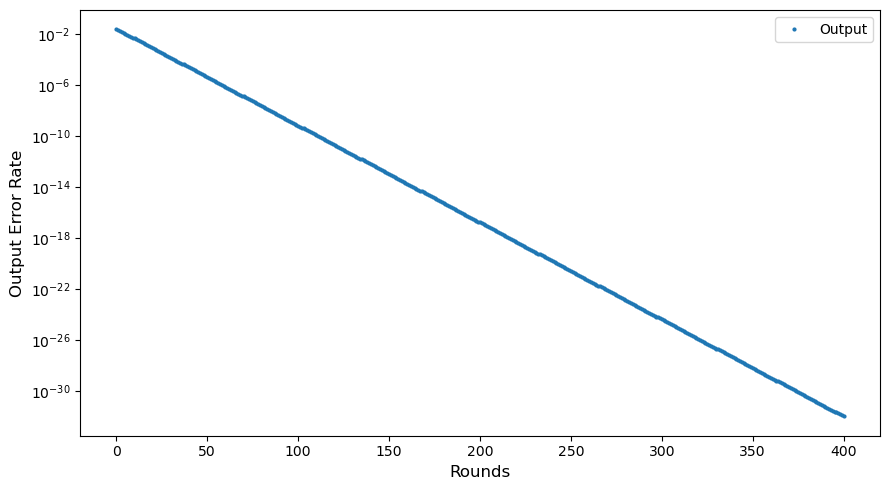

In [8]:
rounds_arr = np.arange(rounds + 1)

# Convert mpmath values to float for plotting
output_error_rate = np.array([
    float(2 * inf)
    for inf in infidelity_list
])

plt.figure(figsize=(9, 5))

plt.plot(rounds_arr, output_error_rate, 'o',
         markersize=2, label='Output')

plt.xlabel("Rounds", fontsize=12)
plt.ylabel("Output Error Rate", fontsize=12)

# Logarithmic y-axis
plt.yscale('log')

ax = plt.gca()

# Display ticks as 10^{-3}, 10^{-4}, etc.
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))

plt.legend()
plt.tight_layout()
plt.show()

In [14]:
np.savez_compressed(
    "../../data/two_qubit/physical_level/multiple_rounds/stable_manifold_error_rates.npz",

    # Axes and starting point on the stable manifold.
    rounds_arr=rounds_arr,
    t=float(t),
    x_in=float(x_in),
    z_in=float(z_in),

    output_error_rate=output_error_rate,
    success_probabilities=np.array([float(p) for p in success_probabilities])
)